# Notebook 7 — FCC-ee: change beta star with open matching

Load the FCC-ee Z lattice and increase both interaction-point beta functions by a factor of **five**, from approximately **90 mm / 0.8 mm** to **450 mm / 4 mm**.

Use the dispersion-free matching sections between the dispersion suppressors (DS) and the interior of the interaction region (IR). Keep the inner IR, final-focus, and dispersive DS magnets fixed.

## Your tasks

1. Load `fccee_z.json`, select `fccee_p_ring`, and calculate nominal periodic 4D Twiss.
2. Select the insertion around `ipd`, bounded by `end_ds_start_straight_ipd` and `end_straight_start_ds_ipd`. Inspect the nominal beta functions, dispersion, and matching quadrupoles.
3. Calculate **open Twiss from each DS boundary to the IP**, using the nominal DS optics as fixed initial conditions. Propagate forwards on the left and backwards on the right.
4. Make $\beta_x^*=5\beta_{x,0}^*$, $\beta_y^*=5\beta_{y,0}^*$, and $\alpha_x^*=\alpha_y^*=0$ the **matching targets at the IP**. Use `solve_homotopy()` on each half-insertion to approach them gradually.
5. Inspect the targets and strengths, compare the optics before and after, and verify the factor-five change with periodic full-ring Twiss.
6. Compare the natural chromaticities of the two optics, using copies with sextupoles switched off.

The DS optics are fixed boundary conditions, while the IP optics are targets. The strength knobs are shared by all four collision insertions, so all four IPs change together. This exercise matches linear transverse optics with radiation off; ring tunes and chromaticities are not matching targets.

See the [Xsuite examples of open matching](https://xsuite.readthedocs.io/en/latest/match.html#match-at-specific-locations).

### Load the lattice and calculate the nominal optics

In [86]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

In [87]:
env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)

tw0 = line.twiss4d()
print(f'Energy: {line.particle_ref.energy0[0] / 1e9:.2f} GeV')
print(f'Circumference: {line.get_length() / 1e3:.3f} km')
print(f'Nominal tunes: {tw0.qx:.5f} / {tw0.qy:.5f}')

Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Energy: 45.60 GeV
Circumference: 90.660 km
Nominal tunes: 166.16000 / 162.20000


### Natural chromaticity of the nominal optics

Natural chromaticity is the tune derivative with respect to relative momentum deviation with the sextupoles switched off. Use a separate copy so that the original lattice and its sextupole settings are preserved. In this lattice, all nonzero sextupole strengths are in `Sextupole` elements.

Use a small momentum step, `delta_chrom=1e-6`: without sextupole correction, the large chromaticity makes the default off-momentum probes unstable.

In [88]:
line_natural = line.copy()
tt_natural = line_natural.get_table()
for name in tt_natural.rows[tt_natural.element_type == 'Sextupole'].name:
    line_natural[name].k2 = 0

tw_natural_0 = line_natural.twiss4d(delta_chrom=1e-6)
print(f'Nominal natural chromaticities: {tw_natural_0.dqx:.3f} / {tw_natural_0.dqy:.3f}')

Nominal natural chromaticities: -512.539 / -3145.903


In [89]:
ip = 'ipd'
start = 'end_ds_start_straight_ipd'
end = 'end_straight_start_ds_ipd'

tw0.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02472
ipd                             22665.1          0.09        0.0008  -5.88247e-09  -2.53742e-08
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02473

### Inspect the insertion and the matching sections

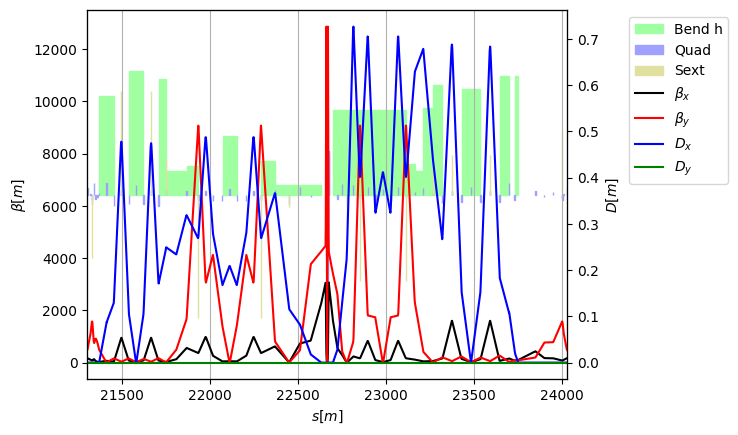

In [90]:
tw0.rows[start:end].plot()

### Select the matching quadrupoles

Vary all quadrupoles in the nominally dispersion-free matching sections between the DS boundaries and the IR bends: **eight on the left** and **seven on the right**.

On the left, use `qd8m`, `qf9m`, `qd10m`, `qd20l`, `qf19l`, `qd18l`, `qf17l`, and `qd16l`. On the right, use `qf17r`, `qd18r`, `qf19r`, `qd20r`, `qd10m`, `qf9m`, and `qd8m`.

The `qd8m`, `qf9m`, and `qd10m` families initially share knobs between the two sides. Give the right-side occurrences separate knobs, leaving the original knobs for the left side. Each knob remains shared across the four collision insertions. Using the complete sections gives more flexibility for larger beta-star changes.

In [ ]:
for family in ['qd8m', 'qf9m', 'qd10m']:
    knob = 'k' + family + 'r'
    env[knob] = env['k' + family]
    for index in [0, 2, 4, 6]:  # Right sides of the four collision insertions
        env.ref[f'{family}.{index}'].k1 = env.ref[knob]

knobs_left = ['kqd16l', 'kqf17l', 'kqd18l', 'kqf19l', 'kqd20l',
              'kqd8m', 'kqf9m', 'kqd10m']
knobs_right = ['kqf17r', 'kqd18r', 'kqf19r', 'kqd20r',
               'kqd8mr', 'kqf9mr', 'kqd10mr']
quad_names = [
    'qd8m.1', 'qf9m.1', 'qd10m.1', 'qd20l.0',
    'qf19l.0', 'qd18l.0', 'qf17l.0', 'qd16l.0',
    'qf17r.1', 'qd18r.1', 'qf19r.1', 'qd20r.1',
    'qd10m.2', 'qf9m.2', 'qd8m.2',
]
tw0.rows[quad_names].cols['s betx bety dx dpx']

### Open Twiss with fixed DS boundary conditions

Each half-insertion has its own nominal DS initialization. For the right half, `init_at=end` propagates the optics backwards from the downstream DS boundary to the IP. Neither calculation imposes periodicity.

In [92]:
init_left = tw0.get_twiss_init(start)
init_right = tw0.get_twiss_init(end)

tw_left = line.twiss4d(start=start, end=ip, init=init_left)
tw_right = line.twiss4d(start=ip, end=end, init=init_right, init_at=end)
tw_left.rows[ip].cols['betx bety alfx alfy']

TwissTable: 1 row, 5 cols
name          betx          bety          alfx          alfy
ipd           0.09        0.0008  -5.88315e-09  -3.03911e-08

In [93]:
tw_right.rows[ip].cols['betx bety alfx alfy']

TwissTable: 1 row, 5 cols
name          betx          bety          alfx          alfy
ipd           0.09        0.0008  -5.72277e-09  -2.87083e-08

### Define the IP targets

Both halves must reach the same enlarged waist. The weights balance the horizontal beta in tenths of metres and vertical beta in millimetres against the alpha targets. The initial conditions at the DS boundaries remain fixed.

In [94]:
env['beta_factor'] = 1
env['betx_star'] = tw0['betx', ip]
env['bety_star'] = tw0['bety', ip]
targets_ip = [
    xt.Target('betx', at=ip, value=env.new_expr('beta_factor * betx_star'), tol=1e-8, weight=10),
    xt.Target('bety', at=ip, value=env.new_expr('beta_factor * bety_star'), tol=1e-10, weight=1000),
    xt.TargetSet(alfx=0, alfy=0, at=ip, tol=1e-7),
]


### Match the left half with homotopy

`solve_homotopy(n_steps=20)` moves the target values in 20 equal steps from their initial values to the requested ones, solving at each step. Here the beta-star factor increases from 1 to 5 in steps of 0.2.

Evaluate `target_status()` before starting, to display and initialize the current target values. If an intermediate solve fails, homotopy can return before reaching the final targets; check the final factor explicitly below.

In [96]:
opt_left = line.match(
    solve=False, method='4d',
    start=start, end=ip, init=init_left,
    vary=xt.VaryList(knobs_left, step=1e-8),
    targets=targets_ip,
    n_steps_max=40,
)
opt_right = line.match(
    solve=False, method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=40,
)
opt_left.target_status()
opt_right.target_status()

Target status:               alty = 3.0956e-07              
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx    True   7.18571e-12          0.09 (vars['beta_factor'] * vars['betx_star'] ... ('betx', 'ipd'), val=(vars['beta_factor' ...
1  ON    ipd_bety    True    1.7534e-12        0.0008 (vars['beta_factor'] * vars['bety_star'] ... ('bety', 'ipd'), val=(vars['beta_factor' ...
2  ON    ipd_alfx    True  -5.88315e-09  -5.88315e-09 0                                            ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -3.03911e-08  -3.03911e-08 0                                            ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
Target status:               alty = 2.9276e-07              
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_b

In [122]:
env['beta_factor'] = 7
opt_left.solve()
opt_right.solve()
opt_left.tag(f"fact{env['beta_factor']:.2f}")
opt_right.tag(f"fact{env['beta_factor']:.2f}")

                                             
Optimize - start penalty: 7.225                                
Matching: model call n. 2541 penalty = 7.2250e+00              
Optimize - end penalty:  7.22496                            


Could not find point within tolerance.
Matching: model call n. 2542 penalty = 7.2250e+00              



RuntimeError: Could not find point within tolerance.

In [123]:
opt_left.reload(tag='fact8.0')

Matching: model call n. 2543 penalty = 1.8062e+00              

In [43]:
opt_left.solve_homotopay(n_steps=20)

                                             
Optimize - start penalty: 0.5419                            
Matching: model call n. 111 penalty = 1.5879e-10              
Optimize - end penalty:  1.58794e-10                            
                                             -10              
Optimize - start penalty: 0.5419                              
Matching: model call n. 218 penalty = 5.2663e-11              
Optimize - end penalty:  5.26631e-11                            
                                             -11              
Optimize - start penalty: 0.5419                              
Matching: model call n. 281 penalty = 5.4133e-11              
Optimize - end penalty:  5.41332e-11                            
                                             -11              
Optimize - start penalty: 0.5419                              
Matching: model call n. 324 penalty = 4.9283e-10              
Optimize - end penalty:  4.92832e-10                            
   

In [44]:
opt_left.target_status()
opt_left.vary_status()

Target status:               penalty = 5.4187e-01              
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx   False       -0.0405         0.738        0.7785 ('betx', 'ipd'), val=0.7785, tol=1e-08,  ...
1  ON    ipd_bety   False      -0.00036       0.00656       0.00692 ('bety', 'ipd'), val=0.00692, tol=1e-10, ...
2  ON    ipd_alfx    True   1.77483e-10   -7.0499e-10  -8.82473e-10 ('alfx', 'ipd'), val=-8.82473e-10, tol=1 ...
3  ON    ipd_alfy    True  -2.27875e-09  -6.83741e-09  -4.55866e-09 ('alfy', 'ipd'), val=-4.55866e-09, tol=1 ...
Vary status:                 
id state tag met name   lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqd16l None            0.0306449 None           0.00276666         1e-08             1
1  ON        OK  kqf17l None          -0.00212071 None           -0.0045356         1e-08             1
2  ON        OK  kqd18l None 

### Match the right half with homotopy

In [14]:
opt_right = line.match(
    solve=False, method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=40,
)
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx   False         -0.36          0.09          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety   False       -0.0032        0.0008         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -5.72277e-09  -5.72277e-09             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -2.87083e-08  -2.87083e-08             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


In [15]:
opt_right.solve_homotopy(n_steps=20)

Optimize - start penalty: 0.2408                         


Matching: model call n. 5 penalty = 2.4083e-01              

Matching: model call n. 6 penalty = 2.4083e-01              

Matching: model call n. 8 penalty = 2.4083e-01              

Matching: model call n. 9 penalty = 2.4083e-01              

Matching: model call n. 27 penalty = 1.6852e-01              

... (75 outputs left out)

Matching: model call n. 780 penalty = 1.7491e-03              


Optimize - end penalty:  3.17762e-10                            


Optimize - start penalty: 0.2408                         



Optimize - end penalty:  4.8055e-10                            


In [16]:
opt_right.target_status()
opt_right.vary_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx    True   1.46543e-11          0.45          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True  -2.89985e-14         0.004         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True   4.56172e-11   4.56172e-11             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True    2.2788e-12    2.2788e-12             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
Vary status:                 
id state tag met name    lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf17r  None           0.00328009 None           0.00839602         1e-08             1
1  ON        OK  kqd18r  None           0.00176903 None          -0.00608779         1e-08             1
2  ON        OK  kqf19r  None           0.00688713 None     

### Check that both halves reach the requested IP optics

In [17]:
tw_left = line.twiss4d(start=start, end=ip, init=init_left)
tw_right = line.twiss4d(start=ip, end=end, init=init_right, init_at=end)

print(f'Left beta-star ratios: {tw_left["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_left["bety", ip] / tw0["bety", ip]:.6f}')
print(f'Right beta-star ratios: {tw_right["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_right["bety", ip] / tw0["bety", ip]:.6f}')

Left beta-star ratios: 5.000000 / 5.000000
Right beta-star ratios: 5.000000 / 5.000000


### Propagate through the complete insertion

Start from the left DS boundary and propagate through both matched halves. Inspect the IP waist and the recovery of the nominal right-DS beta and alpha functions. The small dispersion residuals in the supplied lattice are not matching targets.

In [18]:
tw_match = line.twiss4d(start=start, end=end, init=init_left)
tw_match.rows[[start, ip, end]].cols['betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 7 cols
name                               betx          bety          alfx          alfy            dx ...
end_ds_start_straight_ipd       165.464       476.699      -2.48637      -1.02472  -2.01248e-05
ipd                                0.45         0.004   1.27294e-09  -1.54897e-08  -7.76932e-07
end_straight_start_ds_ipd       165.464       476.699       2.48637       1.02473  -1.37572e-05

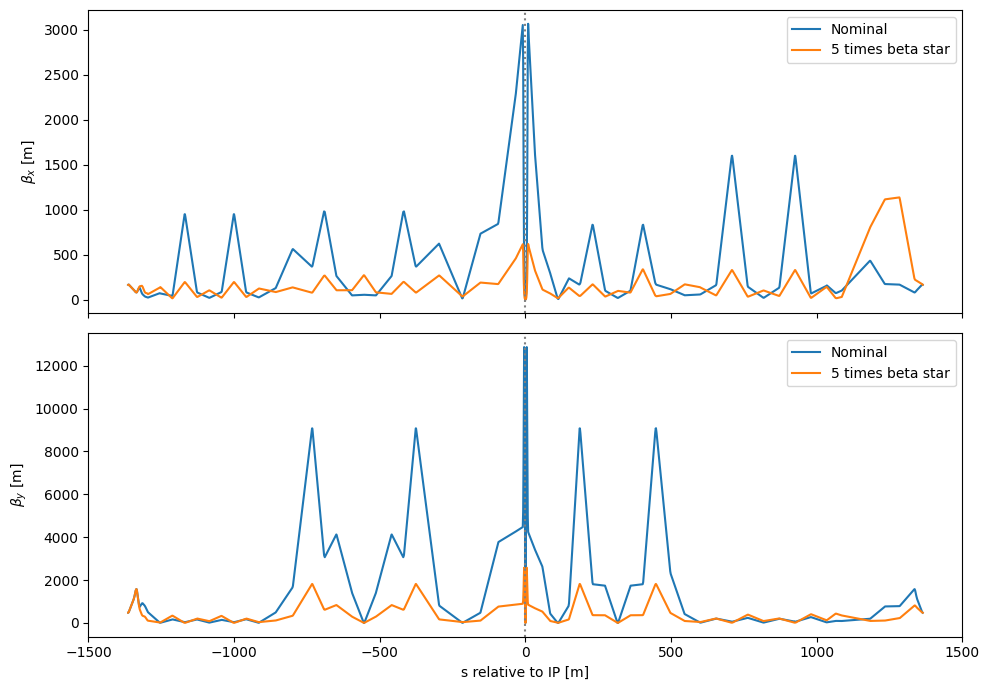

In [19]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
for tw, label in [(tw0.rows[start:end], 'Nominal'), (tw_match, '5 times beta star')]:
    s = tw.s - tw0['s', ip]
    axes[0].plot(s, tw.betx, label=label)
    axes[1].plot(s, tw.bety, label=label)
axes[0].set_ylabel(r'$\beta_x$ [m]')
axes[1].set_ylabel(r'$\beta_y$ [m]')
axes[1].set_xlabel('s relative to IP [m]')
for ax in axes:
    ax.axvline(0, color='grey', linestyle=':')
    ax.legend()
plt.tight_layout()

### Verify the periodic full ring

Recalculate periodic Twiss independently of the open-match initialization. Inspect all four IPs and confirm that the original beta and alpha functions are recovered at the two DS boundaries. The tunes can change because the phase advance through the insertions changes.

In [20]:
tw_ring = line.twiss4d()
tw_ring.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['betx bety alfx alfy dx dpx']

TwissTable: 4 rows, 7 cols
name          betx          bety          alfx          alfy            dx           dpx
ipa           0.45         0.004  -2.23267e-09  -2.87451e-08  -1.56348e-07  -2.22275e-06
ipd           0.45         0.004   2.02432e-09  -2.16795e-08  -7.49624e-07   1.49508e-06
ipg           0.45         0.004   6.06503e-09  -1.94814e-08   4.57241e-07   -1.9476e-06
ipj           0.45         0.004  -6.06929e-09  -1.87498e-08  -1.93484e-07   2.14294e-06

In [21]:
tw_ring.rows[[start, end]].cols['betx bety alfx alfy dx dpx']

TwissTable: 2 rows, 7 cols
name                               betx          bety          alfx          alfy            dx ...
end_ds_start_straight_ipd       165.464       476.698      -2.48637      -1.02472  -1.85868e-05
end_straight_start_ds_ipd       165.464       476.698       2.48637       1.02472  -1.34168e-05

In [22]:
print(f'Nominal tunes: {tw0.qx:.5f} / {tw0.qy:.5f}')
print(f'Matched tunes: {tw_ring.qx:.5f} / {tw_ring.qy:.5f}')
print(f'Beta-star ratios at {ip}: '
      f'{tw_ring["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_ring["bety", ip] / tw0["bety", ip]:.6f}')

Nominal tunes: 166.16000 / 162.20000
Matched tunes: 166.18130 / 162.18632
Beta-star ratios at ipd: 5.000000 / 5.000000


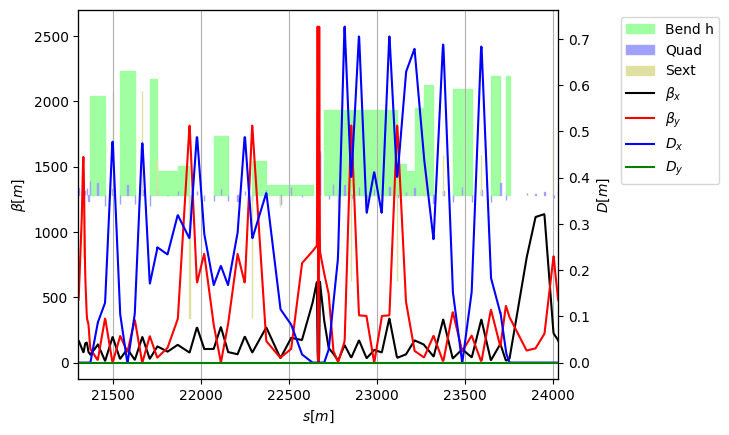

In [23]:
tw.plot()


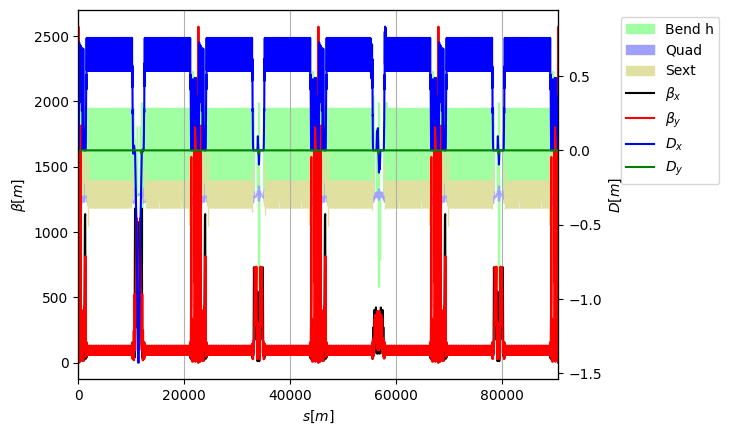

In [24]:
line.twiss().plot()

### Compare natural chromaticities before and after matching

Repeat the calculation with the matched quadrupole strengths and the sextupoles switched off in a new copy. Compare the full-ring natural chromaticities for the nominal and enlarged beta star. The sextupoles in `line` remain at their original settings; `tw0.dqx/dqy` and `tw_ring.dqx/dqy` include their contribution.

Increasing beta star reduces the beta functions in the final-focus quadrupoles and their chromaticity contribution. The total need not scale exactly as $1/\beta^*$: the arcs still contribute, and the matching-section optics and strengths also change.

In [25]:
line_natural = line.copy()
tt_natural = line_natural.get_table()
for name in tt_natural.rows[tt_natural.element_type == 'Sextupole'].name:
    line_natural[name].k2 = 0

tw_natural_5 = line_natural.twiss4d(delta_chrom=1e-6)
print(f'{"Optics":<22} {"Natural Qx prime":>18} {"Natural Qy prime":>18}')
for label, tw_nat in [('Nominal beta star', tw_natural_0),
                      ('5 times beta star', tw_natural_5)]:
    print(f'{label:<22} {tw_nat.dqx:18.3f} {tw_nat.dqy:18.3f}')
print(f'|Chromaticity| ratio (matched / nominal): '
      f'{abs(tw_natural_5.dqx / tw_natural_0.dqx):.3f} / '
      f'{abs(tw_natural_5.dqy / tw_natural_0.dqy):.3f}')

Optics                   Natural Qx prime   Natural Qy prime
Nominal beta star                -512.539          -3145.903
5 times beta star                -244.450           -782.154
|Chromaticity| ratio (matched / nominal): 0.477 / 0.249
